# Câu 2. Nhận dạng ký tự bằng Naïve Bayes và k-Nearest Neighbors (dùng scikit-learn)

- **Dữ liệu:** UCI Letter Recognition – 20.000 mẫu, 26 lớp (A–Z), 16 đặc trưng nguyên (0–15)
- **Chia dữ liệu:** 16.000 mẫu đầu để train, 4.000 mẫu cuối để test (theo khuyến nghị của tác giả)
- **Thuật toán:** `GaussianNB`, `CategoricalNB`, `KNeighborsClassifier` của scikit-learn

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.naive_bayes import GaussianNB, CategoricalNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay

## 1. Đọc dữ liệu và chia train/test

In [2]:
cols = ["letter", "x-box", "y-box", "width", "high", "onpix", "x-bar", "y-bar",
        "x2bar", "y2bar", "xybar", "x2ybr", "xy2br", "x-ege", "xegvy", "y-ege", "yegvx"]
df = pd.read_csv("data/letter-recognition.data", header=None, names=cols)
print(df.shape)
df.head()

(20000, 17)


,letter,x-box,y-box,width,high,onpix,x-bar,y-bar,x2bar,y2bar,xybar,x2ybr,xy2br,x-ege,xegvy,y-ege,yegvx
0,T,2,8,3,5,1,8,13,0,6,6,10,8,0,8,0,8
1,I,5,12,3,7,2,10,5,5,4,13,3,9,2,8,4,10
2,D,4,11,6,8,6,10,6,2,6,10,3,7,3,7,3,9
3,N,7,11,6,6,3,5,9,4,6,4,4,10,6,10,2,8
4,G,2,1,3,1,1,8,6,6,6,6,5,9,1,7,5,10


In [3]:
X = df.drop(columns="letter").values
y = df["letter"].values

X_train, y_train = X[:16000], y[:16000]
X_test,  y_test  = X[16000:], y[16000:]
print("Train:", X_train.shape, "| Test:", X_test.shape)
print("Số lớp:", len(np.unique(y)), "| Giá trị đặc trưng:", X.min(), "->", X.max())

Train: (16000, 16) | Test: (4000, 16)
Số lớp: 26 | Giá trị đặc trưng: 0 -> 15


## 2. Naïve Bayes

- **GaussianNB:** giả định mỗi đặc trưng có phân phối chuẩn theo từng lớp.
- **CategoricalNB:** đặc trưng là số nguyên 0–15 nên coi là biến rời rạc (làm mịn Laplace, `alpha=1`).

In [4]:
results = {}

gnb = GaussianNB().fit(X_train, y_train)
results["Naive Bayes (Gaussian)"] = gnb.predict(X_test)

cnb = CategoricalNB(alpha=1.0, min_categories=16).fit(X_train, y_train)
results["Naive Bayes (Categorical)"] = cnb.predict(X_test)

for name in results:
    print(f"{name:28s} accuracy = {accuracy_score(y_test, results[name])*100:.2f}%")

Naive Bayes (Gaussian)       accuracy = 62.52%
Naive Bayes (Categorical)    accuracy = 72.38%


## 3. k-Nearest Neighbors

Chọn `k` bằng cross-validation 5 fold trên tập train (không dùng tập test để chọn tham số).

In [5]:
ks = [1, 3, 5, 7, 9, 11, 15]
grid = GridSearchCV(KNeighborsClassifier(), {"n_neighbors": ks}, cv=5, n_jobs=-1)
grid.fit(X_train, y_train)

cv = pd.DataFrame({"k": ks, "CV accuracy (%)": grid.cv_results_["mean_test_score"] * 100})
print(cv.to_string(index=False))
print("-> k tốt nhất:", grid.best_params_["n_neighbors"])

 k  CV accuracy (%)
 1         94.93125
 3         94.33750
 5         94.08125
 7         93.74375
 9         93.41875
11         93.07500
15         92.36875
-> k tốt nhất: 1


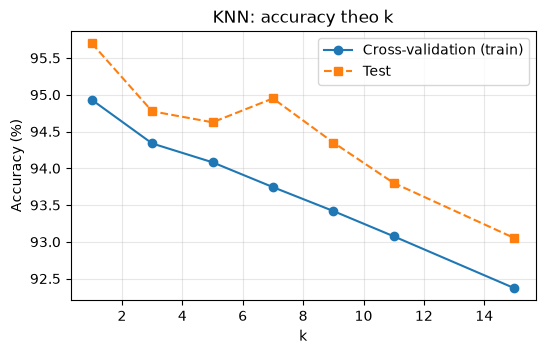

In [6]:
test_acc = []
for k in ks:
    m = KNeighborsClassifier(n_neighbors=k).fit(X_train, y_train)
    test_acc.append(accuracy_score(y_test, m.predict(X_test)) * 100)

plt.figure(figsize=(6, 3.5))
plt.plot(ks, cv["CV accuracy (%)"], "o-", label="Cross-validation (train)")
plt.plot(ks, test_acc, "s--", label="Test")
plt.xlabel("k"); plt.ylabel("Accuracy (%)"); plt.grid(alpha=.3); plt.legend()
plt.title("KNN: accuracy theo k"); plt.show()

best_k = grid.best_params_["n_neighbors"]
knn = grid.best_estimator_
results[f"KNN (k={best_k})"] = knn.predict(X_test)

## 4. So sánh kết quả

                  Mô hình  Accuracy (%)
   Naive Bayes (Gaussian)         62.52
Naive Bayes (Categorical)         72.38
                KNN (k=1)         95.70


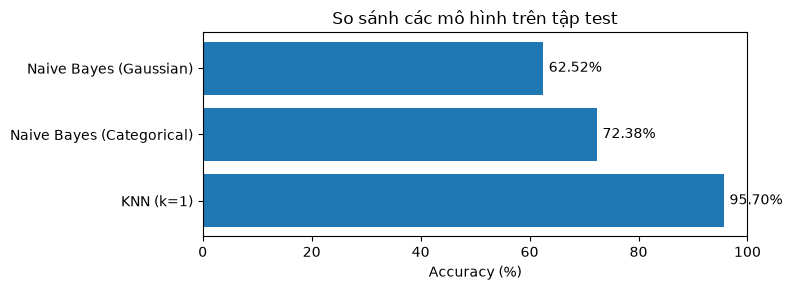

In [7]:
summary = pd.DataFrame({"Mô hình": list(results),
                        "Accuracy (%)": [accuracy_score(y_test, p) * 100 for p in results.values()]})
summary = summary.round(2)
print(summary.to_string(index=False))

plt.figure(figsize=(8, 3))
bars = plt.barh(summary["Mô hình"], summary["Accuracy (%)"])
plt.xlim(0, 100); plt.gca().invert_yaxis(); plt.xlabel("Accuracy (%)")
for b, a in zip(bars, summary["Accuracy (%)"]):
    plt.text(a + 1, b.get_y() + b.get_height()/2, f"{a:.2f}%", va="center")
plt.title("So sánh các mô hình trên tập test"); plt.tight_layout(); plt.show()

## 5. Phân tích lỗi

In [8]:
print(f"Báo cáo chi tiết – KNN (k={best_k})")
print(classification_report(y_test, results[f"KNN (k={best_k})"], digits=3))

Báo cáo chi tiết – KNN (k=1)
              precision    recall  f1-score   support

           A      0.987     0.987     0.987       156
           B      0.922     0.956     0.939       136
           C      0.965     0.965     0.965       142
           D      0.947     0.964     0.955       167
           E      0.959     0.928     0.943       152
           F      0.927     0.915     0.921       153
           G      0.970     0.976     0.973       164
           H      0.897     0.868     0.882       151
           I      0.952     0.970     0.961       165
           J      0.965     0.939     0.952       148
           K      0.917     0.911     0.914       146
           L      0.981     0.968     0.974       157
           M      0.986     0.965     0.975       144
           N      0.975     0.940     0.957       166
           O      0.938     0.986     0.961       139
           P      0.946     0.940     0.943       168
           Q      0.959     0.964     0.961       16

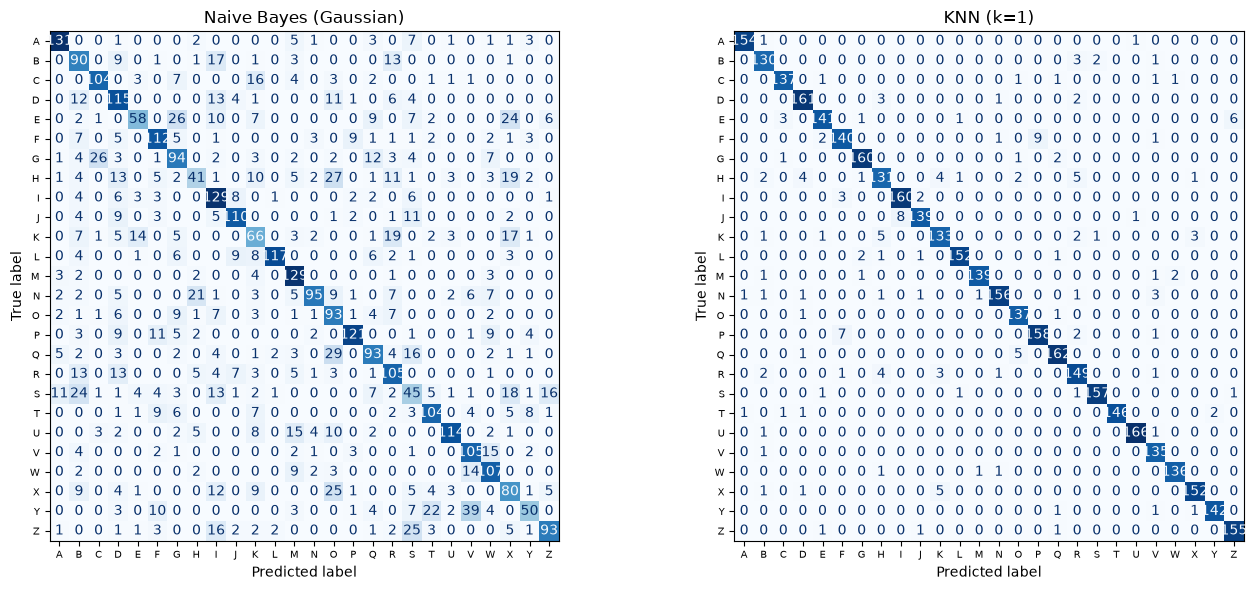

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
for ax, name in zip(axes, ["Naive Bayes (Gaussian)", f"KNN (k={best_k})"]):
    ConfusionMatrixDisplay.from_predictions(y_test, results[name], ax=ax,
                                            colorbar=False, cmap="Blues", xticks_rotation=0)
    ax.set_title(name)
    ax.tick_params(labelsize=7)
plt.tight_layout(); plt.show()

In [10]:
def top_confusions(y_true, y_pred, n=8):
    labels = np.unique(y_true)
    cm = confusion_matrix(y_true, y_pred, labels=labels)
    np.fill_diagonal(cm, 0)
    idx = np.dstack(np.unravel_index(np.argsort(-cm, axis=None)[:n], cm.shape))[0]
    return [(labels[i], labels[j], cm[i, j]) for i, j in idx]

for name in ["Naive Bayes (Gaussian)", f"KNN (k={best_k})"]:
    print(f"{name} – cặp nhầm lẫn nhiều nhất (thật -> dự đoán):")
    for a, b, c in top_confusions(y_test, results[name]):
        print(f"  {a} -> {b}: {c} lần")
    print()

Naive Bayes (Gaussian) – cặp nhầm lẫn nhiều nhất (thật -> dự đoán):
  Y -> V: 39 lần
  Q -> O: 29 lần
  H -> O: 27 lần
  E -> G: 26 lần
  G -> C: 26 lần
  X -> O: 25 lần
  Z -> S: 25 lần
  S -> B: 24 lần

KNN (k=1) – cặp nhầm lẫn nhiều nhất (thật -> dự đoán):
  F -> P: 9 lần
  J -> I: 8 lần
  P -> F: 7 lần
  E -> Z: 6 lần
  K -> H: 5 lần
  X -> K: 5 lần
  Q -> O: 5 lần
  H -> R: 5 lần



## 6. Nhận xét

- **KNN vượt trội Naive Bayes** (~95% so với ~62–72%).
- **Naive Bayes yếu** vì giả định các đặc trưng độc lập không đúng: các đặc trưng (`x2bar`, `y2bar`, `xybar`, ...) đều là moment của cùng một ảnh nên tương quan mạnh. `GaussianNB` còn sai thêm vì đặc trưng là số nguyên 0–15; `CategoricalNB` tốt hơn khoảng 10 điểm phần trăm.
- **KNN** tốt nhất ở k nhỏ và giảm dần khi k tăng.
- **Lỗi còn lại** tập trung ở các cặp chữ có hình dạng gần nhau (F↔P, J→I, E→Z, H→K).
- **Chi phí:** Naive Bayes train/dự đoán rất nhanh; KNN phải so sánh với toàn bộ tập train cho mỗi mẫu test.